# Analisis Data Eksploratif

Notebook ini memeriksa data ISPU DKI Jakarta sebelum masuk ke pipeline: struktur file,
kualitas data, cakupan kalender, pola musiman, hubungan nilai historis dengan target,
dan pembagian data latih/uji. Perhitungan memakai fungsi dari `src/preprocessing.py`
supaya hasilnya sama dengan pipeline utama.


In [1]:
from pathlib import Path
import sys
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

warnings.filterwarnings("ignore")

ROOT = Path.cwd()
while not (ROOT / "data" / "ispu_raw.xls").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

from preprocessing import (
    SPLIT,
    STASIUN,
    TANGGAL,
    TARGET,
    build_daily_panel,
    clean_records,
    load_raw_data,
)

PROCESSED_PATH = ROOT / "data" / "ispu_processed.csv"

plt.rcParams.update(
    {
        "font.family": "DejaVu Sans",
        "font.size": 10,
        "axes.titlesize": 11,
        "axes.titleweight": "bold",
        "axes.edgecolor": "#9ca3af",
        "axes.linewidth": 0.8,
        "legend.frameon": False,
    }
)
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
print("Folder proyek:", ROOT.name)


Folder proyek: zian disuruh revisi skripsi malah daftar lomba data mining_JudulKarya


## 1. Struktur Data Mentah

File berekstensi `.xls`, tetapi isinya tabel HTML. Karena itu data dibaca dengan
`pandas.read_html()`, bukan `read_excel()`.


In [2]:
df_raw = load_raw_data()
print(f"Dataset mentah: {df_raw.shape[0]:,} baris x {df_raw.shape[1]} kolom")
display(df_raw.head())
display(df_raw.dtypes.rename("tipe_data").to_frame())

Dataset mentah: 3,501 baris x 13 kolom


,periode_data,bulan,tanggal,stasiun,pm_sepuluh,pm_duakomalima,sulfur_dioksida,karbon_monoksida,ozon,nitrogen_dioksida,max,parameter_pencemar_kritis,kategori
0,202401,1,21,DKI3 JAGAKARSA,51.0,65.0,45.0,9.0,8.0,79.0,79.0,NaN,SEDANG
1,202401,1,22,DKI3 JAGAKARSA,27.0,34.0,45.0,5.0,8.0,56.0,56.0,NaN,SEDANG
2,202401,1,23,DKI3 JAGAKARSA,NaN,52.0,46.0,6.0,9.0,51.0,52.0,PM25,SEDANG
3,202401,1,24,DKI3 JAGAKARSA,46.0,65.0,46.0,8.0,9.0,38.0,65.0,PM25,SEDANG
4,202401,1,25,DKI3 JAGAKARSA,37.0,55.0,47.0,7.0,11.0,28.0,55.0,PM25,SEDANG


,tipe_data
periode_data,int64
bulan,int64
tanggal,int64
stasiun,object
pm_sepuluh,float64
pm_duakomalima,float64
sulfur_dioksida,float64
karbon_monoksida,float64
ozon,float64
nitrogen_dioksida,float64


## 2. Tanggal, Stasiun, dan Nilai Kosong

Pemeriksaan ini mencakup tanggal tidak valid, variasi penulisan nama stasiun, dan
jumlah nilai kosong. Baris dengan tanggal tidak valid dibuang, bukan ditebak
tanggal penggantinya.


In [3]:
log: dict = {}
df_clean, log = clean_records(df_raw, log)

invalid = pd.DataFrame(log["cleaning"]["tanggal_tidak_valid"])
print(f"Tanggal tidak valid: {len(invalid)} baris")
display(invalid)

aliases = pd.DataFrame(log["cleaning"]["variasi_nama_stasiun"])
print("Variasi nama stasiun dan hasil standardisasi:")
display(aliases)

Tanggal tidak valid: 1 baris


,periode_data,bulan,tanggal,stasiun_raw,stasiun,pm_duakomalima,alasan
0,202509,9,31,DKI5 KEBON JERUK,DKI5 Kebon Jeruk,None,Tanggal tidak ada dalam kalender


Variasi nama stasiun dan hasil standardisasi:


,stasiun_raw,stasiun,jumlah_baris
0,DKI1 BUNDARAN HOTEL INDONESIA (HI),DKI1 Bundaran HI,579
1,DKI1 BUNDARAN HOTEL INDONESIA HI,DKI1 Bundaran HI,31
2,DKI1 BUNDERAN HI,DKI1 Bundaran HI,90
3,DKI2 KELAPA GADING,DKI2 Kelapa Gading,700
4,DKI3 JAGAKARSA,DKI3 Jagakarsa,700
5,DKI4 LUBANG BUAYA,DKI4 Lubang Buaya,700
6,DKI5 KEBON JERUK,DKI5 Kebon Jeruk,550
7,DKI5 KEBON JERUK JAKARTA BARAT,DKI5 Kebon Jeruk,150


,jumlah_kosong,persen_dari_baris
pm_sepuluh,263,7.51
nitrogen_dioksida,68,1.94
pm_duakomalima,60,1.71
sulfur_dioksida,55,1.57
karbon_monoksida,49,1.40
ozon,45,1.29
max,7,0.20


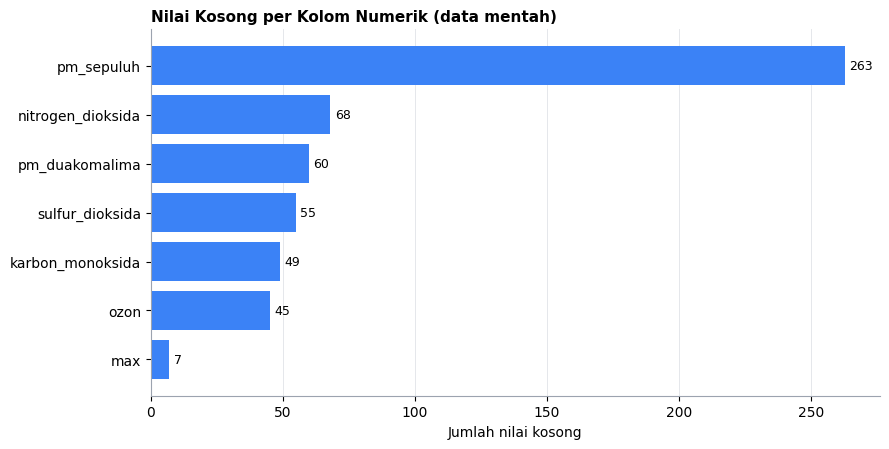

In [4]:
missing_counts = (
    pd.Series(log["cleaning"]["nilai_numerik_kosong"])
    .sort_values(ascending=False)
    .rename("jumlah_kosong")
    .to_frame()
)
missing_counts["persen_dari_baris"] = (
    missing_counts["jumlah_kosong"] / len(df_raw) * 100
).round(2)
display(missing_counts)

plot_data = missing_counts.sort_values("jumlah_kosong")
fig, axis = plt.subplots(figsize=(9, 4.6))
bars = axis.barh(plot_data.index, plot_data["jumlah_kosong"], color="#3b82f6")
axis.bar_label(bars, padding=3, fontsize=9)
axis.set_xlabel("Jumlah nilai kosong")
axis.set_title("Nilai Kosong per Kolom Numerik (data mentah)", loc="left")
axis.spines["top"].set_visible(False)
axis.spines["right"].set_visible(False)
axis.grid(axis="x", color="#e5e7eb", linewidth=0.7)
axis.set_axisbelow(True)
fig.tight_layout()
plt.show()

## 3. Kalender Harian

Setiap stasiun di-reindex ke kalender harian penuh supaya `lag_1` berarti hari
kalender sebelumnya, bukan baris sebelumnya. Nilai yang tidak tersedia dibiarkan
kosong dan sampelnya dikeluarkan saat pembentukan fitur.


In [5]:
panel, log = build_daily_panel(df_clean, log)

coverage = (
    panel.groupby(STASIUN)["pm_duakomalima"]
    .agg(jumlah_hari="size", nilai_valid="count")
)
coverage["nilai_kosong"] = coverage["jumlah_hari"] - coverage["nilai_valid"]
coverage["persen_valid"] = (
    coverage["nilai_valid"] / coverage["jumlah_hari"] * 100
).round(2)
display(coverage)
print(
    "Hari stasiun yang benar-benar hilang dari file:",
    log["kalender"]["jumlah_hari_stasiun_hilang"],
)
print("Rentang kalender:", log["kalender"]["tanggal_mulai"], "s.d.", log["kalender"]["tanggal_selesai"])
print("Jumlah tanggal unik:", log["kalender"]["jumlah_tanggal_unik"])

,jumlah_hari,nilai_valid,nilai_kosong,persen_valid
stasiun,,,,
DKI1 Bundaran HI,700,691,9,98.71
DKI2 Kelapa Gading,700,693,7,99.00
DKI3 Jagakarsa,700,693,7,99.00
DKI4 Lubang Buaya,700,682,18,97.43
DKI5 Kebon Jeruk,700,681,19,97.29


Hari stasiun yang benar-benar hilang dari file: 0
Rentang kalender: 2024-01-01 s.d. 2025-11-30
Jumlah tanggal unik: 700


## 4. Tren Harian Indeks PM2.5

Garis abu-abu adalah nilai harian, garis biru rata-rata bergerak 7 hari, dan garis
putus-putus merah menandai ambang indeks 100.


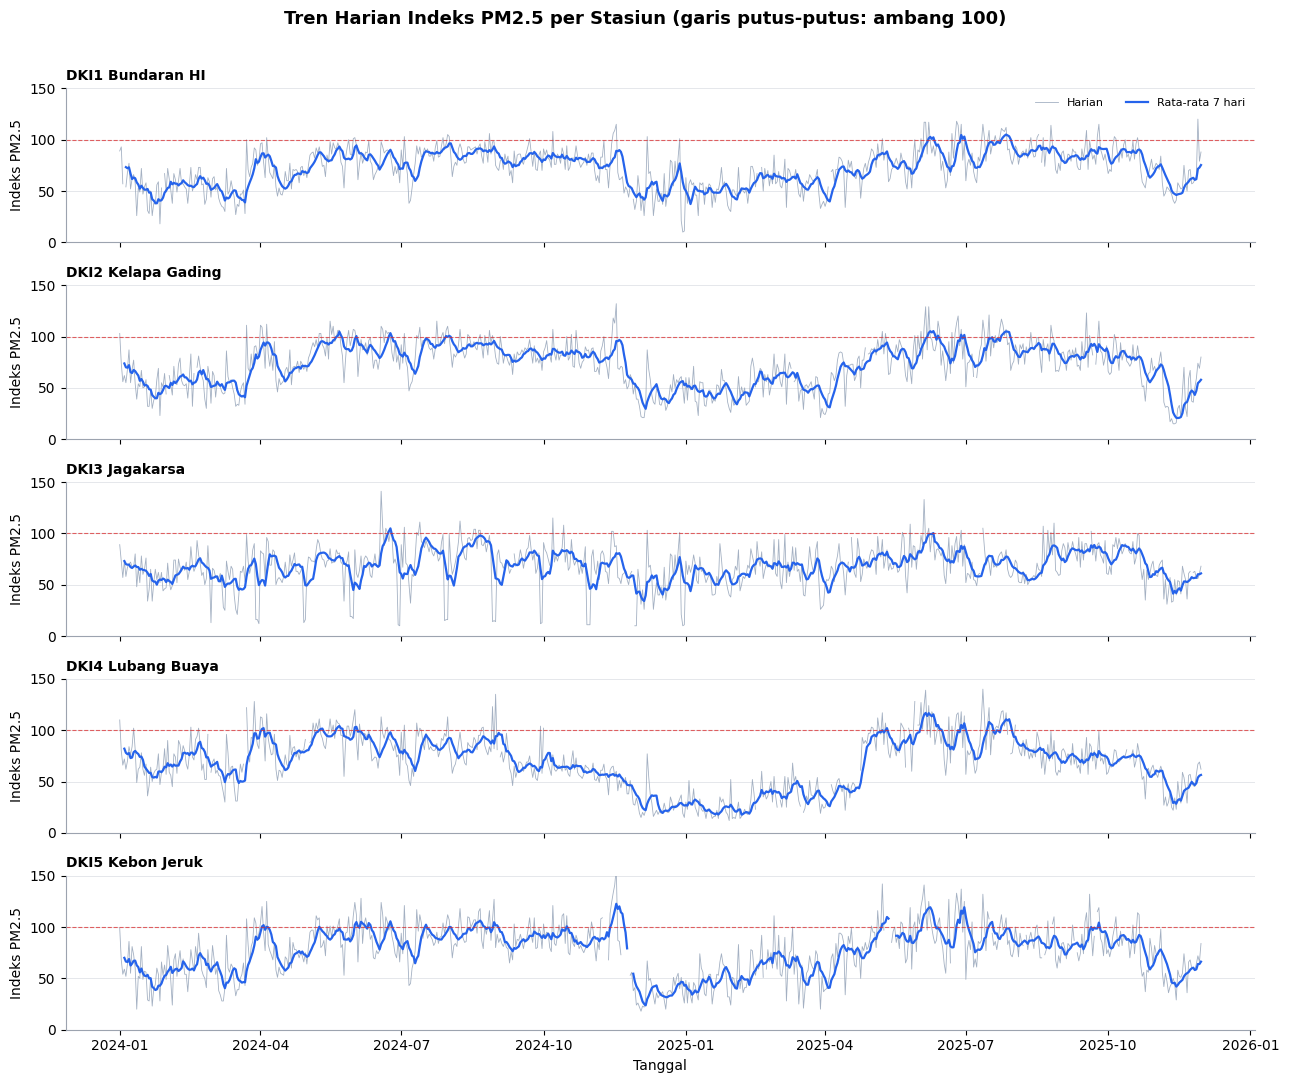

In [6]:
fig, axes = plt.subplots(5, 1, figsize=(13, 11), sharex=True)
for axis, (station, group) in zip(axes, panel.groupby(STASIUN)):
    group = group.sort_values(TANGGAL)
    rolling = group["pm_duakomalima"].rolling(7, min_periods=4).mean()
    axis.plot(
        group[TANGGAL],
        group["pm_duakomalima"],
        color="#94a3b8",
        linewidth=0.6,
        alpha=0.85,
        label="Harian",
    )
    axis.plot(
        group[TANGGAL],
        rolling,
        color="#2563eb",
        linewidth=1.6,
        label="Rata-rata 7 hari",
    )
    axis.axhline(100, color="#dc2626", linestyle="--", linewidth=0.8, alpha=0.7)
    axis.set_title(station, loc="left", fontsize=10)
    axis.set_ylabel("Indeks PM2.5")
    axis.set_ylim(0, 150)
    axis.spines["top"].set_visible(False)
    axis.spines["right"].set_visible(False)
    axis.grid(axis="y", color="#e5e7eb", linewidth=0.7)
    axis.set_axisbelow(True)

axes[0].legend(loc="upper right", ncol=2, fontsize=8)
axes[-1].set_xlabel("Tanggal")
fig.suptitle(
    "Tren Harian Indeks PM2.5 per Stasiun (garis putus-putus: ambang 100)",
    fontsize=13,
    fontweight="bold",
)
fig.tight_layout(rect=(0, 0, 1, 0.97))
plt.show()

## 5. Distribusi dan Pola Bulanan

Boxplot menunjukkan sebaran nilai per stasiun. Grafik kanan menunjukkan rata-rata
bulanan untuk melihat pola musiman pada 2024 dan 2025.


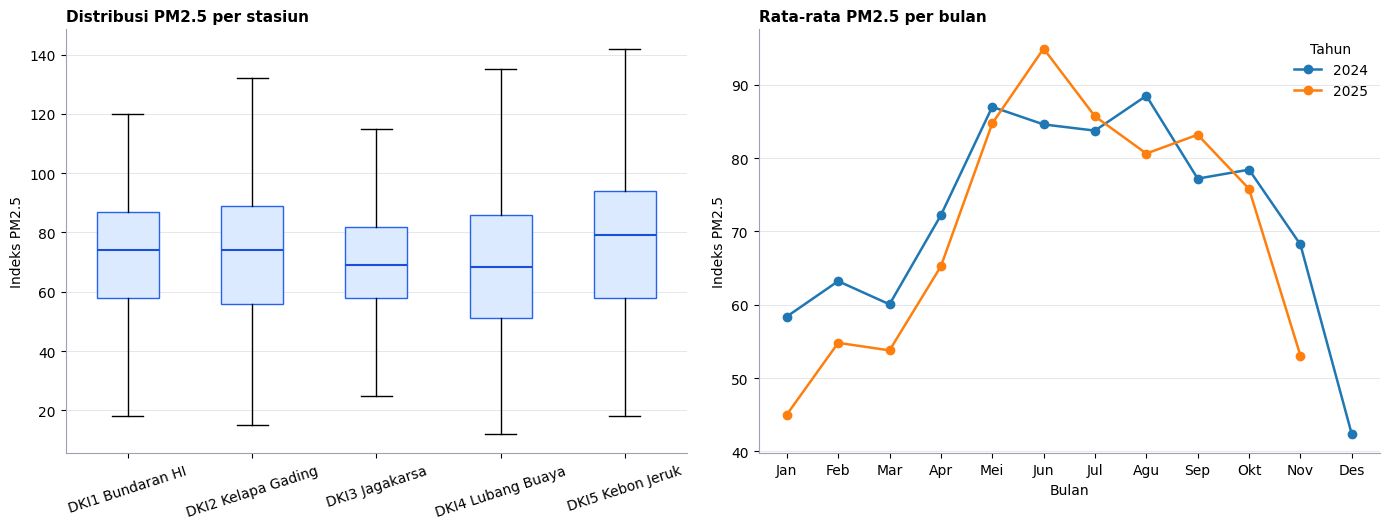

In [7]:
panel["tahun"] = panel[TANGGAL].dt.year
panel["bulan"] = panel[TANGGAL].dt.month

fig, (ax_box, ax_month) = plt.subplots(1, 2, figsize=(14, 5.4))

stations = sorted(panel[STASIUN].unique())
data = [
    panel.loc[panel[STASIUN] == station, "pm_duakomalima"].dropna()
    for station in stations
]
boxplot = ax_box.boxplot(
    data,
    labels=stations,
    patch_artist=True,
    showfliers=False,
    medianprops={"color": "#1d4ed8", "linewidth": 1.5},
)
for patch in boxplot["boxes"]:
    patch.set_facecolor("#dbeafe")
    patch.set_edgecolor("#2563eb")
ax_box.set_title("Distribusi PM2.5 per stasiun", loc="left")
ax_box.set_ylabel("Indeks PM2.5")
ax_box.tick_params(axis="x", rotation=18)
ax_box.spines["top"].set_visible(False)
ax_box.spines["right"].set_visible(False)
ax_box.grid(axis="y", color="#e5e7eb", linewidth=0.7)
ax_box.set_axisbelow(True)

monthly = (
    panel.groupby(["tahun", "bulan"])["pm_duakomalima"]
    .mean()
    .reset_index()
)
for year, group in monthly.groupby("tahun"):
    ax_month.plot(
        group["bulan"],
        group["pm_duakomalima"],
        marker="o",
        linewidth=1.8,
        label=str(year),
    )
ax_month.set_xticks(range(1, 13))
ax_month.set_xticklabels(
    ["Jan", "Feb", "Mar", "Apr", "Mei", "Jun", "Jul", "Agu", "Sep", "Okt", "Nov", "Des"]
)
ax_month.set_title("Rata-rata PM2.5 per bulan", loc="left")
ax_month.set_ylabel("Indeks PM2.5")
ax_month.set_xlabel("Bulan")
ax_month.legend(title="Tahun")
ax_month.spines["top"].set_visible(False)
ax_month.spines["right"].set_visible(False)
ax_month.grid(axis="y", color="#e5e7eb", linewidth=0.7)
ax_month.set_axisbelow(True)

fig.tight_layout()
plt.show()

## 6. Hubungan Nilai Historis dengan Target

Korelasi dan scatter plot dipakai untuk melihat seberapa kuat nilai historis
menjelaskan target, sekaligus memastikan fitur lag/rolling cukup informatif.


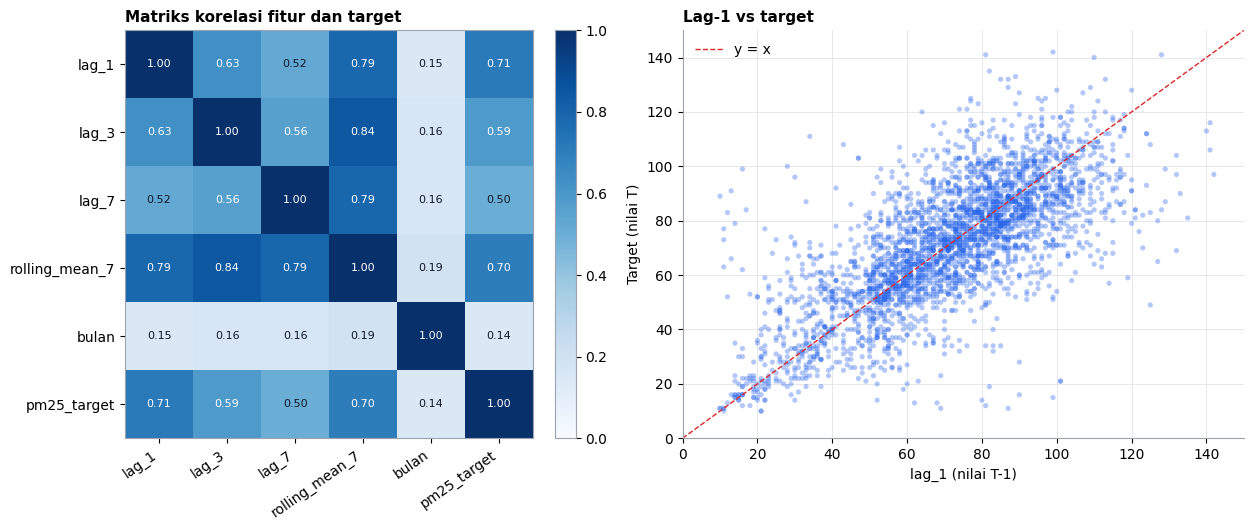

In [8]:
model_df = pd.read_csv(PROCESSED_PATH, parse_dates=[TANGGAL])

correlation_columns = ["lag_1", "lag_3", "lag_7", "rolling_mean_7", "bulan", TARGET]
correlation = model_df[correlation_columns].corr()

fig, (ax_heat, ax_scatter) = plt.subplots(1, 2, figsize=(13.5, 5.4))
image = ax_heat.imshow(correlation, cmap="Blues", vmin=0, vmax=1)
ax_heat.set_xticks(range(len(correlation)), correlation.columns, rotation=35, ha="right")
ax_heat.set_yticks(range(len(correlation)), correlation.columns)
for row in range(len(correlation)):
    for column in range(len(correlation)):
        value = correlation.iloc[row, column]
        ax_heat.text(
            column,
            row,
            f"{value:.2f}",
            ha="center",
            va="center",
            fontsize=8,
            color="white" if value > 0.55 else "#111827",
        )
ax_heat.set_title("Matriks korelasi fitur dan target", loc="left")
fig.colorbar(image, ax=ax_heat, fraction=0.046, pad=0.04)

ax_scatter.scatter(
    model_df["lag_1"],
    model_df[TARGET],
    s=14,
    alpha=0.35,
    color="#2563eb",
    edgecolors="none",
)
limit = [0, 150]
ax_scatter.plot(limit, limit, color="#dc2626", linestyle="--", linewidth=1, label="y = x")
ax_scatter.set_xlim(limit)
ax_scatter.set_ylim(limit)
ax_scatter.set_xlabel("lag_1 (nilai T-1)")
ax_scatter.set_ylabel("Target (nilai T)")
ax_scatter.set_title("Lag-1 vs target", loc="left")
ax_scatter.legend(loc="upper left")
ax_scatter.spines["top"].set_visible(False)
ax_scatter.spines["right"].set_visible(False)
ax_scatter.grid(color="#e5e7eb", linewidth=0.7)
ax_scatter.set_axisbelow(True)

fig.tight_layout()
plt.show()

## 7. Pembagian Data

Split memakai tanggal unik, bukan baris acak, sehingga satu tanggal tidak muncul
di dua bagian. Batas tanggalnya sama untuk semua stasiun.


,jumlah_baris,jumlah_tanggal,mulai,selesai
split,,,,
train,2186,483,2024-01-08,2025-05-04
validation,446,105,2025-05-05,2025-08-17
test,449,105,2025-08-18,2025-11-30


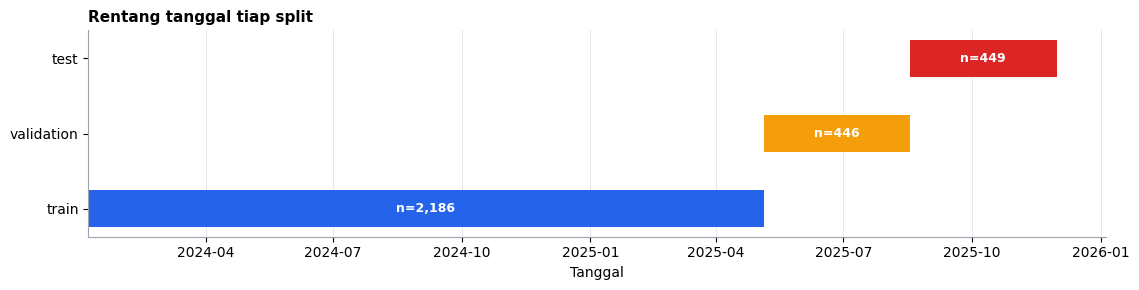

In [9]:
split_summary = (
    model_df.groupby(SPLIT)
    .agg(
        jumlah_baris=(TANGGAL, "size"),
        jumlah_tanggal=(TANGGAL, "nunique"),
        mulai=(TANGGAL, "min"),
        selesai=(TANGGAL, "max"),
    )
    .reindex(["train", "validation", "test"])
)
display(split_summary)

colors = {"train": "#2563eb", "validation": "#f59e0b", "test": "#dc2626"}
fig, axis = plt.subplots(figsize=(11.5, 3.0))
for label in ["train", "validation", "test"]:
    subset = model_df.loc[model_df[SPLIT] == label]
    start, end = subset[TANGGAL].min(), subset[TANGGAL].max()
    axis.barh(
        label,
        (end - start).days + 1,
        left=start,
        height=0.5,
        color=colors[label],
    )
    axis.text(
        start + (end - start) / 2,
        label,
        f"n={len(subset):,}",
        ha="center",
        va="center",
        color="white",
        fontsize=9,
        fontweight="bold",
    )

axis.set_title("Rentang tanggal tiap split", loc="left")
axis.set_xlabel("Tanggal")
axis.spines["top"].set_visible(False)
axis.spines["right"].set_visible(False)
axis.grid(axis="x", color="#e5e7eb", linewidth=0.7)
axis.set_axisbelow(True)
fig.tight_layout()
plt.show()

## 8. Ringkasan


In [10]:
target = model_df[TARGET]
print(f"Jumlah sampel siap model : {len(model_df):,}")
print(f"Rentang target            : {target.min():.0f} - {target.max():.0f}")
print(f"Rata-rata / median target : {target.mean():.2f} / {target.median():.2f}")
print(f"Standar deviasi target    : {target.std(ddof=1):.2f}")
print(f"Proporsi target > 100     : {(target > 100).mean() * 100:.2f}%")
print()
print("Rata-rata target per stasiun:")
print(model_df.groupby(STASIUN)[TARGET].mean().round(2).to_string())
print()
print("Korelasi lag_1 dengan target :", round(model_df["lag_1"].corr(target), 3))
print("Korelasi rolling_mean_7      :", round(model_df["rolling_mean_7"].corr(target), 3))

Jumlah sampel siap model : 3,081
Rentang target            : 10 - 142
Rata-rata / median target : 71.21 / 73.00
Standar deviasi target    : 23.08
Proporsi target > 100     : 9.44%

Rata-rata target per stasiun:
stasiun
DKI1 Bundaran HI      73.28
DKI2 Kelapa Gading    72.69
DKI3 Jagakarsa        68.16
DKI4 Lubang Buaya     66.55
DKI5 Kebon Jeruk      75.15

Korelasi lag_1 dengan target : 0.714
Korelasi rolling_mean_7      : 0.702


## 9. Catatan

Dataset mentah berisi 3.501 baris dan 13 kolom, mencakup 700 tanggal (1 Januari 2024
sampai 30 November 2025) dan lima stasiun. Satu baris bertanggal 31 September 2025
(DKI5 Kebon Jeruk) dibuang karena tanggalnya tidak ada. Baris itu tercatat di
`outputs/preprocessing_log.json`, dan tanggal penggantinya tidak ditebak.

PM2.5 kosong pada 61 baris mentah. Nilai kosong tidak diimputasi, sehingga sampel
dengan target kosong atau riwayat lag/rolling tidak lengkap dikeluarkan. Tersisa
3.081 sampel siap model. Blok kosong terpanjang adalah empat hari berturut-turut di
DKI5 (10-13 Mei 2025).

Rata-rata PM2.5 lebih tinggi pada Mei-Oktober dan lebih rendah pada Desember-Februari.
Puncak rata-rata bulanan ada pada Juni 2025 (93,1 poin) dan titik terendah pada
Desember 2024 (42,4 poin).

`lag_1` dan `rolling_mean_7` punya korelasi tertinggi terhadap target, sekitar 0,71
dan 0,70. Keduanya juga menjadi fitur dominan pada model XGBoost.

Train memuat 490 tanggal, validation 105 tanggal, dan test 105 tanggal. Karena fitur
riwayat butuh tujuh hari, baris train efektif dimulai 8 Januari 2024. Test tidak
dipakai untuk memilih hyperparameter.
